# CO₂ Emissions Trends of the World's Top 10 Emitters, 1960–2019

China, the United States, India, Russia, Japan, Iran, Germany, Indonesia, South Korea and Saudi Arabia together produce roughly two-thirds of global CO₂ emissions. This notebook looks at how their emissions have changed over six decades:

1. How have total emissions changed, and when did China overtake the US?
2. Which countries have **peaked**, and how far have they come down since?
3. How have emissions changed since the 1990 Kyoto baseline?
4. Which decades saw the fastest growth for each country?
5. Where were emissions heading in the 2010s?

*Data: annual CO₂ emissions in kilotons, World Bank series, as provided in Emory's QTM 151 course materials. I first used this data in that course; the analysis here is my own.*

In [1]:
import glob, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
NAMES = {"china": "China", "united_states": "United States", "india": "India", "russian_federation": "Russia",
         "japan": "Japan", "iran_islamic_rep": "Iran", "germany": "Germany", "indonesia": "Indonesia",
         "korea_rep": "South Korea", "saudi_arabia": "Saudi Arabia"}

frames = []
for f in glob.glob("data/*_co2_emissions.csv"):
    key = re.search(r"data/(.*)_co2_emissions.csv", f.replace("\\", "/")).group(1)
    frames.append(pd.read_csv(f).assign(country=NAMES[key]))
long = pd.concat(frames)
wide = long.pivot(index="year", columns="country", values="total_emissions") / 1e6   # kilotons -> gigatonnes
wide.round(2).tail()

country,China,Germany,India,Indonesia,Iran,Japan,Russia,Saudi Arabia,South Korea,United States
year,,,,,,,,,,
2015,9.86,0.74,2.16,0.49,0.60,1.18,1.59,0.57,0.61,4.99
2016,9.87,0.75,2.20,0.48,0.61,1.17,1.57,0.56,0.62,4.89
2017,10.10,0.73,2.32,0.52,0.63,1.16,1.59,0.55,0.63,4.82
2018,10.50,0.71,2.45,0.58,0.64,1.12,1.66,0.52,0.63,4.98
2019,10.71,0.66,2.46,0.62,0.63,1.08,1.70,0.52,0.61,4.82


### Data cleaning: Russia before 1990
Russia's series drops from 3.86 Gt in 1989 to 2.16 Gt in 1990, a 44% fall in one year. That isn't a real collapse: the pre-1990 values are for the whole **Soviet Union**. Comparing them with the Russian Federation would be misleading, so I set them to missing. Germany's series starts in 1990, after reunification.

In [2]:
print(wide.loc[1987:1992, "Russia"].round(2).to_string())
wide.loc[:1989, "Russia"] = np.nan
coverage = wide.apply(lambda s: f"{int(s.first_valid_index())}–{int(s.last_valid_index())}")
coverage.to_frame("years covered").T

year
1987    3.85
1988    3.95
1989    3.86
1990    2.16
1991    2.14
1992    2.03


country,China,Germany,India,Indonesia,Iran,Japan,Russia,Saudi Arabia,South Korea,United States
years covered,1960–2019,1990–2019,1960–2019,1960–2019,1960–2019,1960–2019,1990–2019,1960–2019,1960–2019,1960–2019


## 1. Total emissions over time

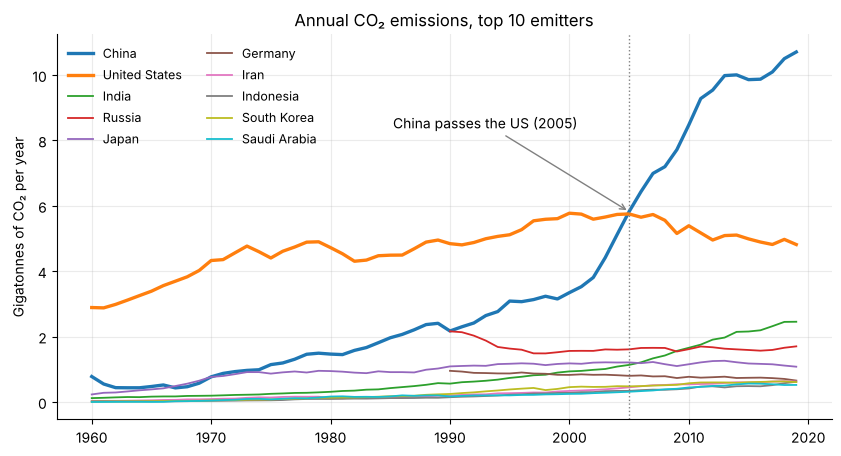

In 2019 China emitted 10.7 Gt, 2.2x the US (4.8 Gt)


In [3]:
order = wide.iloc[-1].sort_values(ascending=False).index
colors = dict(zip(order, plt.cm.tab10.colors))
fig, ax = plt.subplots()
for c in order:
    ax.plot(wide.index, wide[c], label=c, color=colors[c], lw=2.4 if c in ("China", "United States") else 1.3)
cross = wide.index[(wide["China"] > wide["United States"])].min()
ax.axvline(cross, color="grey", ls=":", lw=1)
ax.annotate(f"China passes the US ({cross})", (cross, wide.loc[cross, "China"]), xytext=(-170, 60),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_ylabel("Gigatonnes of CO₂ per year"); ax.set_title("Annual CO₂ emissions, top 10 emitters")
ax.legend(frameon=False, ncol=2, fontsize=9)
plt.savefig("figures/emissions_over_time.png", dpi=150, bbox_inches="tight"); plt.show()

ratio = wide.loc[2019, "China"] / wide.loc[2019, "United States"]
print(f"In 2019 China emitted {wide.loc[2019,'China']:.1f} Gt, {ratio:.1f}x the US ({wide.loc[2019,'United States']:.1f} Gt)")

### Share of the group's total

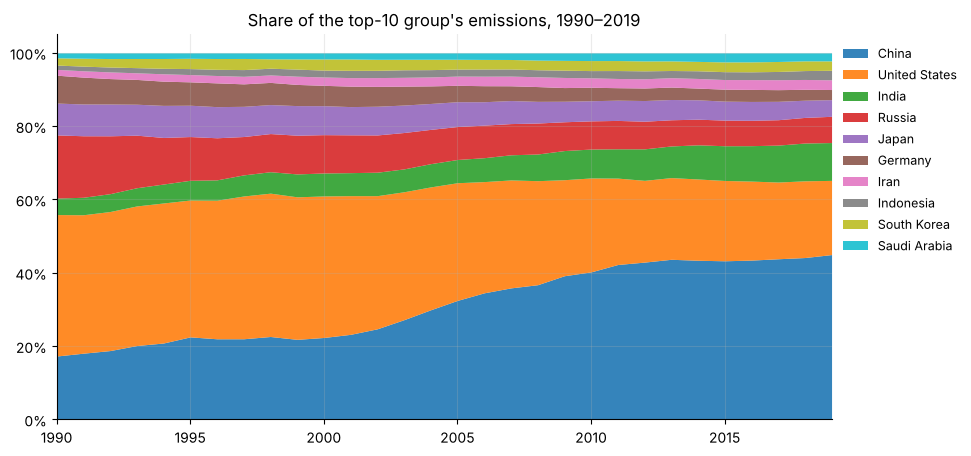

year,1990,2000,2010,2019
country,,,,
China,17%,22%,40%,45%
United States,39%,39%,26%,20%
India,4%,6%,8%,10%
Russia,17%,10%,8%,7%
Japan,9%,8%,5%,5%
Germany,8%,6%,4%,3%
Iran,2%,2%,3%,3%
Indonesia,1%,2%,2%,3%
South Korea,2%,3%,3%,3%


In [4]:
share = wide.loc[1990:].div(wide.loc[1990:].sum(axis=1), axis=0)
ax = share[order].plot(kind="area", stacked=True, color=[colors[c] for c in order], lw=0, alpha=.9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.margins(0, 0)
ax.set_title("Share of the top-10 group's emissions, 1990–2019"); ax.set_xlabel(""); ax.legend(frameon=False, bbox_to_anchor=(1, 1), fontsize=9)
plt.savefig("figures/share_of_total.png", dpi=150, bbox_inches="tight"); plt.show()
share.loc[[1990, 2000, 2010, 2019], order].T.map("{:.0%}".format)

## 2. Who has peaked?
For each country I find its highest emissions year and how far 2019 is below that peak. I count a country as **peaked** if its peak was at least 5 years before 2019 and it is now at least 5% below it.

In [5]:
peak = pd.DataFrame({"Peak year": wide.idxmax().astype(int), "Peak (Gt)": wide.max(), "2019 (Gt)": wide.loc[2019]})
peak["Change from peak"] = peak["2019 (Gt)"] / peak["Peak (Gt)"] - 1
peak["Peaked?"] = np.where((peak["Peak year"] <= 2014) & (peak["Change from peak"] <= -.05), "Yes", "Not yet")
peak = peak.sort_values("Change from peak")
peak.style.format({"Peak (Gt)": "{:.2f}", "2019 (Gt)": "{:.2f}", "Change from peak": "{:.0%}"})

,Peak year,Peak (Gt),2019 (Gt),Change from peak,Peaked?
country,,,,,
Germany,1990,0.96,0.66,-31%,Yes
Russia,1990,2.16,1.70,-21%,Yes
United States,2000,5.78,4.82,-17%,Yes
Japan,2013,1.26,1.08,-14%,Yes
Saudi Arabia,2015,0.57,0.52,-7%,Not yet
South Korea,2018,0.63,0.61,-3%,Not yet
Iran,2018,0.64,0.63,-1%,Not yet
Indonesia,2019,0.62,0.62,0%,Not yet
India,2019,2.46,2.46,0%,Not yet


## 3. Change since the 1990 Kyoto baseline

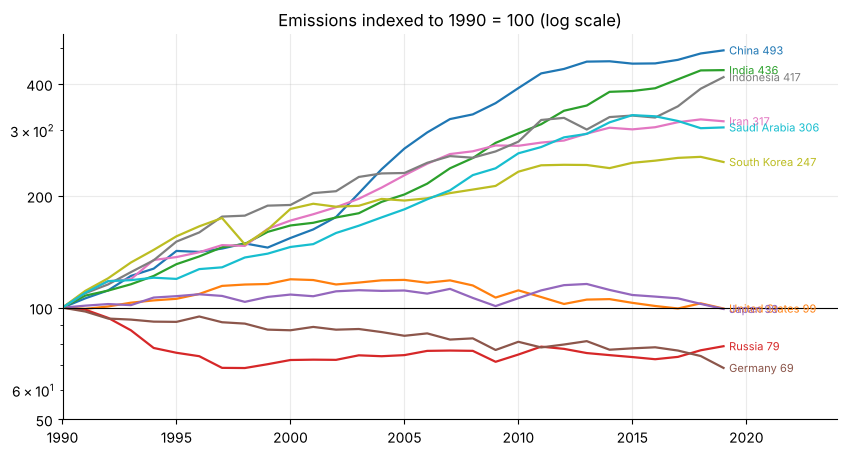

In [6]:
idx = wide.loc[1990:] / wide.loc[1990] * 100
fig, ax = plt.subplots()
for c in order:
    ax.plot(idx.index, idx[c], color=colors[c], lw=1.6)
    ax.annotate(f"{c} {idx.loc[2019, c]:.0f}", (2019, idx.loc[2019, c]), xytext=(4, 0), textcoords="offset points",
                fontsize=8, color=colors[c], va="center")
ax.axhline(100, color="black", lw=.8); ax.set_yscale("log")
ax.set_yticks([50, 100, 200, 400]); ax.yaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_xlim(1990, 2024); ax.set_title("Emissions indexed to 1990 = 100 (log scale)")
plt.savefig("figures/indexed_1990.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Growth rate by decade
Compound annual growth rate of emissions within each decade.

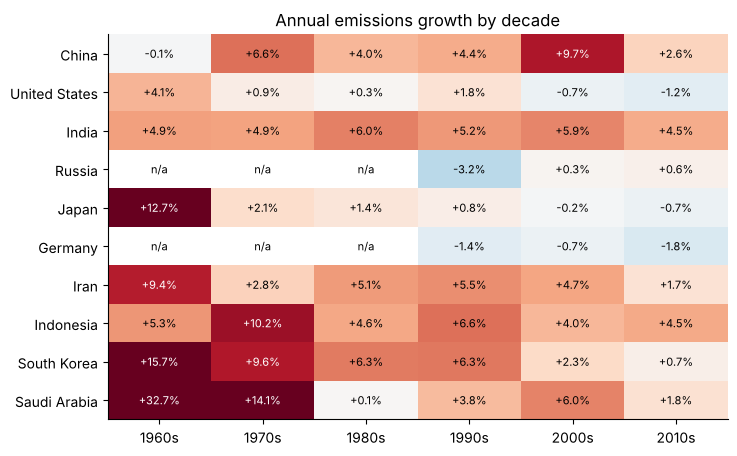

In [7]:
def cagr(a, b, c):
    s = wide[c]
    return (s.loc[b] / s.loc[a]) ** (1 / (b - a)) - 1 if pd.notna(s.loc[a]) and pd.notna(s.loc[b]) else np.nan

decades = [(1960, 1970), (1970, 1980), (1980, 1990), (1990, 2000), (2000, 2010), (2010, 2019)]
growth = pd.DataFrame({f"{a}s": {c: cagr(a, b, c) for c in order} for a, b in decades})

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(growth, cmap="RdBu_r", vmin=-.12, vmax=.12, aspect="auto")
ax.set_xticks(range(growth.shape[1]), growth.columns); ax.set_yticks(range(len(growth)), growth.index)
for i in range(growth.shape[0]):
    for j in range(growth.shape[1]):
        v = growth.iat[i, j]
        ax.text(j, i, "n/a" if np.isnan(v) else f"{v:+.1%}", ha="center", va="center", fontsize=8,
                color="white" if abs(np.nan_to_num(v)) > .08 else "black")
ax.grid(False); ax.set_title("Annual emissions growth by decade")
plt.savefig("figures/growth_by_decade.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Where were emissions heading in the 2010s?
A straight-line trend fitted to 2010–2019 shows each country's recent direction, as a percent of its 2019 level per year. This describes the recent past. It is not a forecast: emissions respond to policy, energy prices and shocks like COVID-19 in 2020.

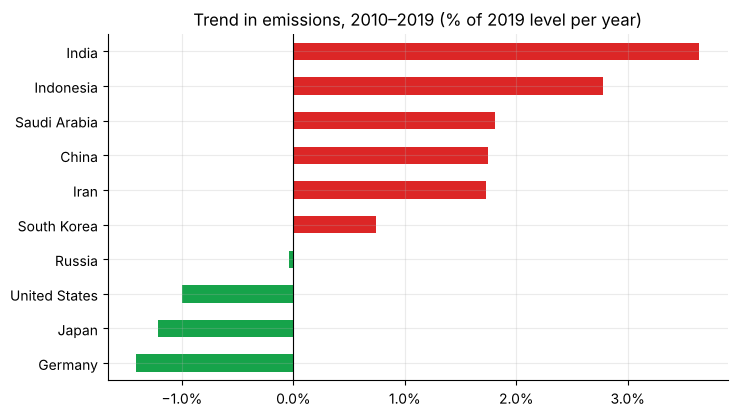

country,Germany,Japan,United States,Russia,South Korea,Iran,China,Saudi Arabia,Indonesia,India
trend per year,-1.4%,-1.2%,-1.0%,-0.0%,+0.7%,+1.7%,+1.8%,+1.8%,+2.8%,+3.6%


In [8]:
recent = wide.loc[2010:2019]
slope = recent.apply(lambda s: np.polyfit(s.index, s.values, 1)[0]) / wide.loc[2019]
slope = slope.sort_values()
ax = slope.plot(kind="barh", color=["#16a34a" if v < 0 else "#dc2626" for v in slope], figsize=(8, 4.5))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.axvline(0, color="black", lw=.8)
ax.set_title("Trend in emissions, 2010–2019 (% of 2019 level per year)"); ax.set_ylabel("")
plt.savefig("figures/trend_2010s.png", dpi=150, bbox_inches="tight"); plt.show()
slope.map("{:+.1%}".format).to_frame("trend per year").T

## Takeaways

1. **China passed the US in 2005, and by 2019 it emitted 2.2× as much** (10.7 Gt vs 4.8 Gt), 45% of this group's total. Its fastest growth came in the 2000s (+9.7% a year), and it slowed sharply to +2.6% a year in the 2010s.
2. **Four countries have clearly peaked:** Germany (-31% since 1990), Russia (-21%, mostly from the post-Soviet industrial collapse), the United States (-17% from its peak in 2000) and Japan (-14% since 2013). Saudi Arabia is 7% below a 2015 peak, which is too recent to call a lasting decline.
3. **Since the 1990 Kyoto baseline, the group split in two.** Germany, Russia, Japan and the US are at or below their 1990 levels. China (5×), India (4.4×) and Indonesia (4.2×) have grown several times over.
4. **Growth followed industrialization.** Japan and South Korea grew 13–16% a year in the 1960s and then slowed decade by decade. India is the only country that has grown steadily at about 5% a year in every decade.
5. **The 2010s pointed in two directions:** rich economies falling about 1% a year, while India (+3.6%), Indonesia (+2.8%) and China (+1.8%) were still rising.

*Limitations:* these are territorial emissions, so they don't count emissions embedded in imported goods. The data stops at 2019, before the COVID-19 dip and rebound. Per-person comparisons would need population data, which this dataset doesn't include.